---
# Task 5: Model Evaluation

## 1. Objective and Evaluation Protocol (Malignant = Positive Class)

In Task 4 the five algorithms (KNN, Decision Tree, Random Forest, ANN, SVM) were tuned **using the training set only** (5-fold group-aware cross-validation). In this task each tuned pipeline is evaluated **once** on the **held-out test set** (139 records, 20% of the data) that was never used for preprocessing, tuning, or model selection.

**Protocol**

- **Positive class = Malignant (`1`)**, negative class = Benign (`0`), as required.
- The saved pipelines (`models/*.joblib`) contain imputation, scaling (where needed) and the model, all fitted on the training data only, so raw test features can be passed in directly with no leakage.
- Test data is used for **reporting**, not for changing hyperparameters.
## 2. Explanation of the Evaluation Metrics

Let **TP** = malignant correctly flagged, **FN** = malignant missed (predicted benign), **FP** = benign wrongly flagged malignant, **TN** = benign correctly cleared.

| Metric | Formula | Meaning in this project |
|:---|:---|:---|
| **Accuracy** | (TP + TN) / (TP + TN + FP + FN) | Share of all patients classified correctly. Can look good even when the minority class is handled poorly (here only ~35% are malignant). |
| **Precision** | TP / (TP + FP) | Of the cases flagged malignant, how many truly are. Low precision means unnecessary biopsies and patient anxiety (false alarms). |
| **Recall (sensitivity)** | TP / (TP + FN) | Of all truly malignant cases, how many are caught. **The most critical metric clinically**, because a missed cancer (FN) is the most harmful error. |
| **F1-score** | 2 · Precision · Recall / (Precision + Recall) | Harmonic mean of precision and recall; one number that is low if either one is low. |
| **ROC-AUC** | Area under the TPR-vs-FPR curve over all thresholds | Threshold-independent ability to rank malignant cases above benign ones (0.5 = random, 1.0 = perfect). |
| **Confusion matrix** | 2 × 2 table of TP, FP, FN, TN | Shows exactly *which* kind of mistakes each model makes. |


## 3. Loading the Test Set and the Trained Models


In [5]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix)

RANDOM_STATE = 42
POSITIVE_CLASS = 1          # 1 = Malignant (positive class), 0 = Benign
CLASS_NAMES = ["Benign", "Malignant"]

MODEL_COLORS = {
    "KNN": "#2b7bba",
    "Decision Tree": "#e67e22",
    "Random Forest": "#27ae60",
    "ANN (MLP)": "#8e44ad",
    "SVM": "#d9534f",
}
MODEL_FILES = {
    "KNN": "knn", "Decision Tree": "decision_tree", "Random Forest": "random_forest",
    "ANN (MLP)": "ann_mlp", "SVM": "svm",
}

# ---- 1. Load the exact train/test split saved in Task 4 (raw, un-imputed features) ----
split_df = pd.read_csv(os.path.join("data", "train_test_split.csv"))
feature_cols = [c for c in split_df.columns
                if c not in ("row_index", "sample_code_number", "class", "split")]

train_part = split_df[split_df["split"] == "train"]
test_part = split_df[split_df["split"] == "test"]

X_eval = test_part[feature_cols]
y_eval = test_part["class"].astype(int)

# ---- 2. Integrity checks on the held-out test set ----
shared_ids = set(train_part["sample_code_number"]) & set(test_part["sample_code_number"])
assert len(train_part) == 552 and len(test_part) == 139
assert len(shared_ids) == 0, "Patient IDs leak between train and test"
if "X_test" in globals():   # when the whole notebook is run top-to-bottom, cross-check with Task 2's split
    assert set(test_part["row_index"]) == set(X_test.index), "Test rows differ from Task 2 split"

print(f"Held-out test set : {X_eval.shape[0]} records x {X_eval.shape[1]} features")
print(f"Malignant (positive) : {int(y_eval.sum())}  ({y_eval.mean():.1%})")
print(f"Benign (negative)    : {int((1 - y_eval).sum())}  ({1 - y_eval.mean():.1%})")
print(f"Missing raw values in test features (handled by each pipeline's imputer): {int(X_eval.isna().sum().sum())}")
print(f"Patient IDs shared with the training set: {len(shared_ids)}")

# ---- 3. Load the five tuned pipelines saved in Task 4 (imputer -> scaler -> model, fitted on training data only) ----
models = {name: joblib.load(os.path.join("models", f"{f}_pipeline.joblib")) for name, f in MODEL_FILES.items()}
for name, m in models.items():
    print(f"Loaded {name:<14} -> steps: {[s for s, _ in m.steps]}")


def get_scores(model, X):
    """Continuous malignancy score used for ROC-AUC: P(malignant) if available, else the SVM margin."""
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X)[:, 1]
    return model.decision_function(X)


Held-out test set : 139 records x 9 features
Malignant (positive) : 48  (34.5%)
Benign (negative)    : 91  (65.5%)
Missing raw values in test features (handled by each pipeline's imputer): 3
Patient IDs shared with the training set: 0
Loaded KNN            -> steps: ['imputer', 'scaler', 'model']
Loaded Decision Tree  -> steps: ['imputer', 'model']
Loaded Random Forest  -> steps: ['imputer', 'model']
Loaded ANN (MLP)      -> steps: ['imputer', 'scaler', 'model']
Loaded SVM            -> steps: ['imputer', 'scaler', 'model']


c:\Users\computer\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator SimpleImputer from version 1.8.0 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
c:\Users\computer\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.8.0 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
c:\Users\computer\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle

## 4. Evaluation of All Models: Accuracy, Precision, Recall, F1-score, ROC-AUC (One Comparison Table)


In [6]:
# Predict once on the untouched test set and compute every required metric (malignant = positive class)
preds, scores, rows = {}, {}, []
for name, model in models.items():
    preds[name] = model.predict(X_eval)
    scores[name] = get_scores(model, X_eval)
    tn, fp, fn, tp = confusion_matrix(y_eval, preds[name], labels=[0, 1]).ravel()
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_eval, preds[name]),
        "Precision": precision_score(y_eval, preds[name], pos_label=POSITIVE_CLASS, zero_division=0),
        "Recall": recall_score(y_eval, preds[name], pos_label=POSITIVE_CLASS),
        "F1-score": f1_score(y_eval, preds[name], pos_label=POSITIVE_CLASS),
        "ROC-AUC": roc_auc_score(y_eval, scores[name]),
        "TP": tp, "FP": fp, "FN": fn, "TN": tn,
    })

results = pd.DataFrame(rows).set_index("Model")
METRIC_COLS = ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]

print("Test-set performance of all five tuned models (n = 139, positive class = Malignant):\n")
display(results.round(4))

print("\nBest value per metric:")
for m in METRIC_COLS:
    best = results[m].max()
    winners = ", ".join(results.index[results[m] == best])
    print(f"  {m:<10} {best:.4f}  ->  {winners}")

os.makedirs("models", exist_ok=True)
results.round(6).to_csv(os.path.join("models", "test_results_summary.csv"))
print("\nSaved -> models/test_results_summary.csv")


Test-set performance of all five tuned models (n = 139, positive class = Malignant):



,Accuracy,Precision,Recall,F1-score,ROC-AUC,TP,FP,FN,TN
Model,,,,,,,,,
KNN,0.9856,0.9792,0.9792,0.9792,0.9867,47,1,1,90
Decision Tree,0.9065,0.8070,0.9583,0.8762,0.9665,46,11,2,80
Random Forest,0.9784,0.9412,1.0000,0.9697,0.9982,48,3,0,88
ANN (MLP),0.9856,0.9600,1.0000,0.9796,0.9998,48,2,0,89
SVM,0.9640,0.9057,1.0000,0.9505,0.9998,48,5,0,86



Best value per metric:
  Accuracy   0.9856  ->  KNN, ANN (MLP)
  Precision  0.9792  ->  KNN
  Recall     1.0000  ->  Random Forest, ANN (MLP), SVM
  F1-score   0.9796  ->  ANN (MLP)
  ROC-AUC    0.9998  ->  ANN (MLP)

Saved -> models/test_results_summary.csv


### Interpretation: Comparison Table

- **Recall:** Random Forest, ANN and SVM all reach **1.000**: they detect all 48 malignant test cases. KNN misses 1 (0.979) and the Decision Tree misses 2 (0.958).
- **Precision / false alarms:** KNN is the most precise (0.979, only 1 false alarm), followed by ANN (0.960), Random Forest (0.941) and SVM (0.906). The Decision Tree is clearly the weakest (0.807; 11 benign cases flagged as malignant).
- **F1-score:** ANN (**0.980**) and KNN (0.979) are practically tied at the top, then Random Forest (0.970), SVM (0.951) and the Decision Tree (0.876).
- **ROC-AUC:** ANN and SVM are the highest (0.9998), then Random Forest (0.998), KNN (0.987) and the Decision Tree (0.966). All five models rank malignant above benign cases very well, so the SVM's lower precision comes from its decision threshold, not from poor ranking.
- **Accuracy:** KNN and ANN share the top (0.986, 2 errors out of 139).


## 5. Confusion Matrices


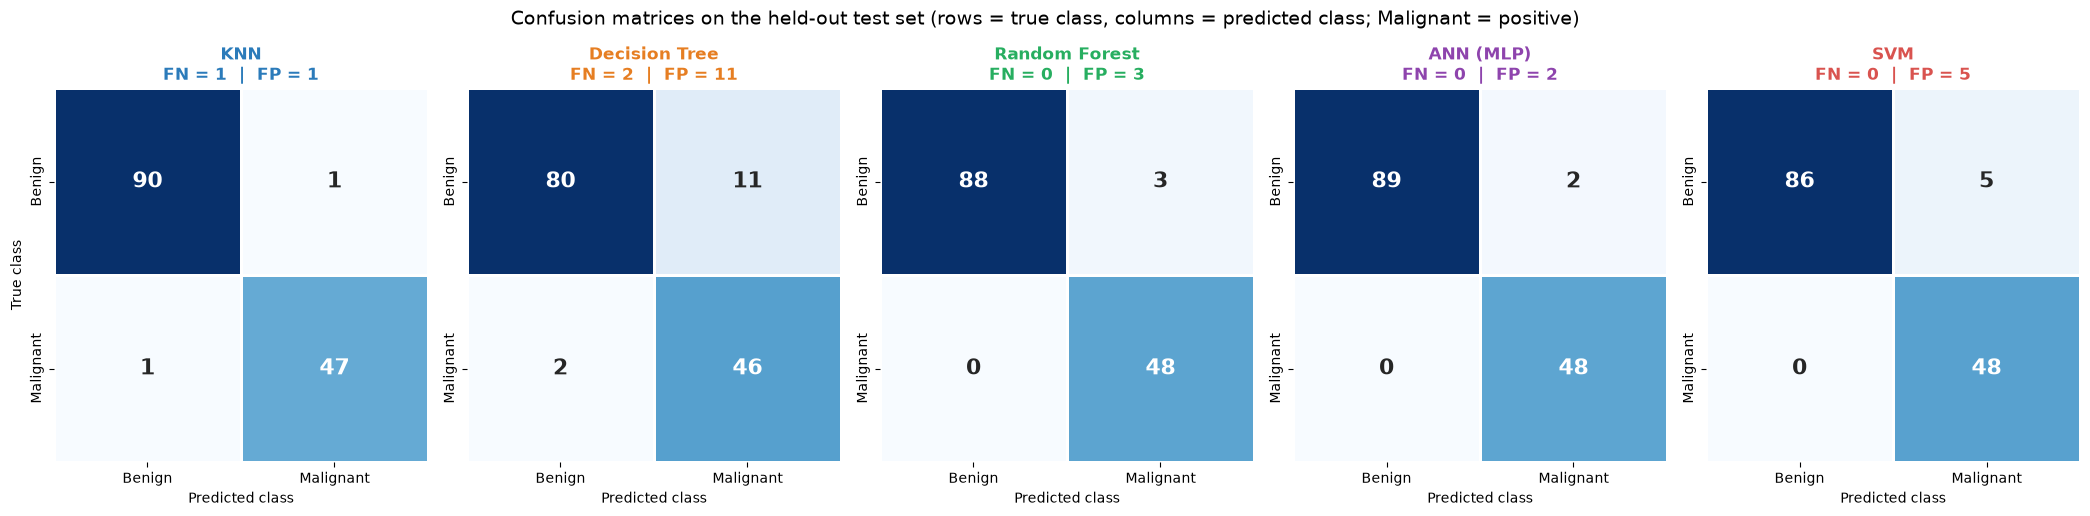

,TP,TN,FP,FN,Total errors
Model,,,,,
KNN,47,90,1,1,2
Decision Tree,46,80,11,2,13
Random Forest,48,88,3,0,3
ANN (MLP),48,89,2,0,2
SVM,48,86,5,0,5


In [7]:
fig, axes = plt.subplots(1, 5, figsize=(21, 4.6))
for ax, (name, y_pred) in zip(axes, preds.items()):
    cm = confusion_matrix(y_eval, y_pred, labels=[0, 1])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, square=True,
                annot_kws={"size": 16, "weight": "bold"}, linewidths=1, linecolor="white",
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax)
    ax.set_title(f"{name}\nFN = {cm[1, 0]}  |  FP = {cm[0, 1]}", fontsize=12, color=MODEL_COLORS[name], fontweight="bold")
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("True class" if ax is axes[0] else "")
fig.suptitle("Confusion matrices on the held-out test set (rows = true class, columns = predicted class; Malignant = positive)",
             fontsize=14, y=1.04)
plt.tight_layout()
plt.show()

cm_table = results[["TP", "FP", "FN", "TN"]].copy()
cm_table["Missed cancers (FN)"] = cm_table["FN"]
cm_table["False alarms (FP)"] = cm_table["FP"]
cm_table["Total errors"] = cm_table["FN"] + cm_table["FP"]
display(cm_table[["TP", "TN", "FP", "FN", "Total errors"]])


### Interpretation: Confusion Matrices

- **Random Forest, ANN and SVM have zero false negatives**: no malignant case is missed. They differ only in false alarms: ANN 2, Random Forest 3, SVM 5.
- **KNN** makes just 2 errors in total (1 FN, 1 FP): the best overall error count, but one malignant case is missed.
- **Decision Tree** makes 13 errors (11 FP, 2 FN). It is the only model whose errors are clearly more than a handful, consistent with its weaker CV scores and the loss of information from a depth-3 tree.
- In a screening setting a false alarm leads to a follow-up test, while a missed cancer can delay treatment, so the **FN column carries more weight** than the FP column.


## 6. Model Comparison and Best Overall Model

**Selection rule** (stated before looking at the ranking, based on the clinical objective):

1. **Highest recall** for the malignant class, because missing a cancer is the costliest error;
2. ties broken by **F1-score**, which accounts for false alarms;
3. remaining ties broken by **ROC-AUC**.


In [8]:
# Transparent selection rule (decided from the clinical objective, then applied to the test results):
#   1) highest Recall  (a missed malignant case is the most costly error)
#   2) then highest F1-score (balances recall with precision / false alarms)
#   3) then highest ROC-AUC (threshold-independent ranking quality)
ranking = results[METRIC_COLS].sort_values(["Recall", "F1-score", "ROC-AUC"], ascending=False)
ranking.insert(0, "Rank", range(1, len(ranking) + 1))
print("Models ranked by the rule  Recall -> F1-score -> ROC-AUC:")
display(ranking.round(4))

best_model = ranking.index[0]
print(f"\nBest overall model on the test set: {best_model}")


Models ranked by the rule  Recall -> F1-score -> ROC-AUC:


,Rank,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,,
ANN (MLP),1,0.9856,0.9600,1.0000,0.9796,0.9998
Random Forest,2,0.9784,0.9412,1.0000,0.9697,0.9982
SVM,3,0.9640,0.9057,1.0000,0.9505,0.9998
KNN,4,0.9856,0.9792,0.9792,0.9792,0.9867
Decision Tree,5,0.9065,0.8070,0.9583,0.8762,0.9665



Best overall model on the test set: ANN (MLP)


### Interpretation: Best Model and Justification

**Best overall model: ANN (MLP)** — one hidden layer of 8 ReLU neurons, selected by the rule above.

Why the ANN:

- **Recall = 1.000** (0 missed malignant cases), tied with Random Forest and SVM.
- Among those three it has the **fewest false alarms (2)**, hence the best precision (0.960) and F1 (0.980).
- **Highest ROC-AUC** (0.9998, tied with SVM) on the test set, and also the highest ROC-AUC in cross-validation (0.992), so this is not just a test-set coincidence.
- Joint-best accuracy (0.986), tied with KNN, with only 2 errors in 139.

Honest caveats:

- **Random Forest** was the top model in cross-validation (CV F2 0.974) and is a very close second on the test set (3 false alarms vs 2). **KNN** has almost the same F1 (0.979) but missed one cancer.
- The test set is small (139 records, 48 malignant): a single case changes recall by about 2 percentage points, so the top models differ by only a few cases.
- The **Decision Tree** is the weakest model on every important metric, although it is the most interpretable. If interpretability matters more than the last point of accuracy, Random Forest (feature importances) is a good alternative.


## Task 5 Summary

### Q&A

- **Were all models evaluated on the same held-out test set?** Yes. The five tuned pipelines from Task 4 were evaluated once on the same 139 test records (48 malignant, 91 benign), with no patient ID shared with the training set.
- **Which metrics were reported?** Accuracy, precision, recall, F1-score and ROC-AUC (malignant = positive class), plus a confusion matrix per model, all in a single comparison table.
- **Which model performs best overall?** The **ANN (MLP)**: recall 1.000, precision 0.960, F1 0.980, ROC-AUC 0.9998, accuracy 0.986 (2 false positives, 0 false negatives).
- **Which models were close behind?** Random Forest (recall 1.000, F1 0.970), KNN (F1 0.979, but 1 missed cancer) and SVM (recall 1.000, but 5 false alarms). The Decision Tree is clearly the weakest (F1 0.876, 13 errors).


Test metrics are saved to `models/test_results_summary.csv`.
